# Новое обещание доставки: анализ эксперимента

Самостоятельный проект студента, глава 5. Источник — выданный ab_promise.csv, сессии 1–21 декабря. Текст плана расположен до расчётов; выводы относятся к назначенным сессиям.

# План до расчёта чисел

Единица назначения — сессия, поскольку группы назначали на сессию. Анализирую сессии, а опоздания описываю среди сделанных заказов; постоянного ID нет, поэтому связь повторных сессий и перенос опыта гостя проверить нельзя. Подвыборка заказов могла измениться под действием обещания, поэтому снижение доли опозданий не доказывает ускорение тех же доставок.

Единственный анализ — после завершения 21 декабря; не продлевать до первого удобного p. Проверяю уникальность session_id, период, группы, SRM при .01 и построчное соответствие promise_min зоне: <2 — 30 в A и 40 в B, [2,5) — 45, >=5 — 60.

H0 главной метрики: доля опозданий среди заказов одинакова в A и B. Двусторонний z-тест, alpha .05; ищу значимое снижение B-A, сообщаю разницу с 95%-м интервалом. Конверсию оцениваю по всем сессиям и заранее определенным зонам; рейтинги только среди оценивших.

Защитная метрика — средний amount на назначенную сессию с нулями у незаказавших. Допустимая потеря delta=10 рублей, сравниваю полный неокругленный нижний предел 95%-го нормального интервала B-A с -10, верхний с -10 для доказанного недопустимого вреда. Уэлч проверяет равенство средних, но безопасность оцениваю по интервалу.

Правило: неисправный SRM или отсутствие значимого снижения опозданий — не внедрять. Если опоздания снизились значимо и весь интервал выручки ниже -10 — не внедрять. Если нижняя граница выше -10 — внедрять. Иначе неопределённо, требуется новый заранее спланированный этап. Не округлять до решения.

Перенос правила: если до запуска другая команда согласовала delta=25, то при значимом снижении опозданий сравню нижнюю границу выручки B-A с -25, а не с нулём и не с -10. Нижняя -23 выше -25: такая потеря исключена этим интервалом.

Города — проверка устойчивости с Холмом по всем городам. Покажу два графика долей с Уилсоном и отдельно интервал разницы в тексте. Финал — три предложения руководителю: решение, число с интервалом, ограничение.


## 1. Проверка данных и дизайна
Ожидаю уникальные сессии, две группы, полный экспериментальный период и построчное совпадение обещаний. SRM — необходимая проверка, которая сама по себе не доказывает независимость наблюдений.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
ab=pd.read_csv("ab_promise.csv",parse_dates=["ts"])
orders=ab[ab.ordered.eq(1)]
sizes=ab.group.value_counts().sort_index()
srm_p=stats.chisquare(sizes).pvalue
short=ab[ab.distance_km<2]
promise_ok=bool(short.loc[short.group.eq("A"),"promise_min"].eq(30).all() and short.loc[short.group.eq("B"),"promise_min"].eq(40).all())
far_same=bool(ab.loc[ab.distance_km.between(2,5,inclusive="left"),"promise_min"].eq(45).all() and ab.loc[ab.distance_km>=5,"promise_min"].eq(60).all())
from IPython.display import display, Markdown
print("Форма:",ab.shape,"Дубликаты session_id:",ab.session_id.duplicated().sum())
print("Период:",ab.ts.min(),ab.ts.max())
display(ab.isna().sum().rename("missing").to_frame())
display(sizes.rename("sessions").to_frame())
print("SRM p:",srm_p,"promise_ok:",promise_ok,"far_same:",far_same)
assert ab.session_id.is_unique
assert set(ab.group)=={"A","B"}
assert promise_ok and far_same
print("Флаги заказов:",sorted(ab.ordered.unique()))
print("Сумма без заказа:",ab.loc[ab.ordered.eq(0),"amount"].sum())

Форма: (7895, 12) Дубликаты session_id: 0
Период: 2026-12-01 09:00:00 2026-12-21 21:53:00


,missing
session_id,0
ts,0
group,0
city,0
distance_km,0
promise_min,0
ordered,0
courier,5229
amount,0
actual_min,5229


,sessions
group,
A,3924
B,3971


SRM p: 0.5968340779632235 promise_ok: True far_same: True
Флаги заказов: [np.int64(0), np.int64(1)]
Сумма без заказа: 0


## 2. Главная метрика
Знаменатель — число заказов; это доля нарушенных обещаний, а не скорость одной и той же доставки. Отбор в заказ может измениться при новом обещании. Привожу интервал разницы B−A отдельно от интервалов отдельных долей.

In [2]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
ab=pd.read_csv("ab_promise.csv",parse_dates=["ts"])
orders=ab[ab.ordered.eq(1)]
def share_result(df,metric):
    a=df.loc[df.group.eq("A"),metric]
    b=df.loc[df.group.eq("B"),metric]
    d=b.mean()-a.mean()
    se=np.sqrt(a.mean()*(1-a.mean())/len(a)+b.mean()*(1-b.mean())/len(b))
    p=proportions_ztest([b.sum(),a.sum()],[len(b),len(a)])[1]
    return a.mean(),b.mean(),d,d-1.96*se,d+1.96*se,p
a,b,d,lo,hi,p_late=share_result(orders,"late")
late_a=round(a,4)
late_b=round(b,4)
diff_pp=round(d*100,1)
ci=(round(lo*100,1),round(hi*100,1))
g=orders.groupby("group").late.agg(["sum","size","mean"])
display(g)
print("Разница B-A, п.п.:",diff_pp,"95% ДИ:",ci,"p:",p_late)

,sum,size,mean
group,,,
A,362.0,1365,0.265201
B,175.0,1301,0.134512


Разница B-A, п.п.: -13.1 95% ДИ: (np.float64(-16.1), np.float64(-10.1)) p: 4.096761840572387e-17


## 3. Конверсия
Все сессии сохраняются в знаменателе. Зоны заданы заранее и используют строгую границу <2 км.

In [3]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
ab=pd.read_csv("ab_promise.csv",parse_dates=["ts"])
orders=ab[ab.ordered.eq(1)]
def share_result(df,metric):
    a=df.loc[df.group.eq("A"),metric]
    b=df.loc[df.group.eq("B"),metric]
    d=b.mean()-a.mean()
    se=np.sqrt(a.mean()*(1-a.mean())/len(a)+b.mean()*(1-b.mean())/len(b))
    p=proportions_ztest([b.sum(),a.sum()],[len(b),len(a)])[1]
    return a.mean(),b.mean(),d,d-1.96*se,d+1.96*se,p
a,b,d,lo,hi,p_all=share_result(ab,"ordered")
d_all=round(d*100,2)
a,b,d,lo,hi,p_short=share_result(ab[ab.distance_km<2],"ordered")
d_short=round(d*100,2)
a,b,d,lo,hi,p_far=share_result(ab[ab.distance_km>=2],"ordered")
d_far=round(d*100,2)
conversion_rows=[]
for label,x in [("все",ab),("<2 км",ab[ab.distance_km<2]),(">=2 км",ab[ab.distance_km>=2])]:
    a,b,d,lo,hi,p=share_result(x,"ordered")
    conversion_rows.append({"zone":label,"A":a,"B":b,"diff_pp":d*100,"lo_pp":lo*100,"hi_pp":hi*100,"p":p})
conv_table=pd.DataFrame(conversion_rows).set_index("zone")
display(conv_table)

,A,B,diff_pp,lo_pp,hi_pp,p
zone,,,,,,
все,0.347859,0.327625,-2.023404,-4.109545,0.062736,0.057330
<2 км,0.353429,0.317181,-3.624817,-7.191907,-0.057727,0.046487
>=2 км,0.345013,0.333078,-1.193567,-3.765264,1.378130,0.363026


## 4. Оценки гостей
Манна–Уитни проверяет распределения по рангам; средние ниже описательные. Пропуски оценок не заменяю пятёрками. Данные описывают мнение оценивших заказчиков.

In [4]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
ab=pd.read_csv("ab_promise.csv",parse_dates=["ts"])
orders=ab[ab.ordered.eq(1)]
r=orders.dropna(subset=["rating"])
a=r.loc[r.group.eq("A"),"rating"]
b=r.loc[r.group.eq("B"),"rating"]
rating_a=round(a.mean(),2)
rating_b=round(b.mean(),2)
low_a=round((a<=4).mean(),3)
low_b=round((b<=4).mean(),3)
p_rating=stats.mannwhitneyu(a,b).pvalue
display(pd.DataFrame({"rating_mean":[rating_a,rating_b],"share_not_5":[low_a,low_b]},index=["A","B"]))
print("Манна–Уитни p:",p_rating)
display(orders.groupby("group").rating.apply(lambda x:x.notna().mean()).rename("rated_share").to_frame())

,rating_mean,share_not_5
A,4.46,0.362
B,4.64,0.269


Манна–Уитни p: 6.96221496216511e-05


,rated_share
group,
A,0.519414
B,0.560338


## 5. Выручка на назначенную сессию
Сохраняю нули у незаказавших. Проверяемый параметр — средняя выручка: Уэлч и заранее выбранная нормальная аппроксимация интервала. Важна граница допустимой потери −10 ₽. Решение предшествует округлению.

In [5]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
ab=pd.read_csv("ab_promise.csv",parse_dates=["ts"])
orders=ab[ab.ordered.eq(1)]
a=ab.loc[ab.group.eq("A"),"amount"]
b=ab.loc[ab.group.eq("B"),"amount"]
d=b.mean()-a.mean()
se=np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))
rev_lo=d-1.96*se
rev_hi=d+1.96*se
rev_a=round(a.mean(),1)
rev_b=round(b.mean(),1)
p_rev=stats.ttest_ind(b,a,equal_var=False).pvalue
rev_diff_full=b.mean()-a.mean()
rev_lo_full,rev_hi_full=rev_lo,rev_hi
display(ab.groupby("group").amount.agg(["size","mean","std"]))
print("B-A:",rev_diff_full,"95% ДИ:",(rev_lo_full,rev_hi_full),"Уэлч p:",p_rev)
print("Нижняя > -10:",rev_lo_full>-10,"Верхняя < -10:",rev_hi_full<-10)

,size,mean,std
group,,,
A,3924,206.063456,352.294924
B,3971,193.083858,347.223912


B-A: -12.979597687207786 95% ДИ: (np.float64(-28.411421825528713), np.float64(2.452226451113143)) Уэлч p: 0.09928130930636497
Нижняя > -10: False Верхняя < -10: False


## 6. Устойчивость по городам
Считаю все городские проверки и поправку Холма; p и p_holm не округляю. Отсутствие значимости в одном городе не доказывает отсутствия эффекта.

In [6]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
ab=pd.read_csv("ab_promise.csv",parse_dates=["ts"])
orders=ab[ab.ordered.eq(1)]
def share_result(df,metric):
    a=df.loc[df.group.eq("A"),metric]
    b=df.loc[df.group.eq("B"),metric]
    d=b.mean()-a.mean()
    se=np.sqrt(a.mean()*(1-a.mean())/len(a)+b.mean()*(1-b.mean())/len(b))
    p=proportions_ztest([b.sum(),a.sum()],[len(b),len(a)])[1]
    return a.mean(),b.mean(),d,d-1.96*se,d+1.96*se,p
from statsmodels.stats.multitest import multipletests
rows=[]
for city,x in orders.groupby("city"):
    a,b,d,lo,hi,p=share_result(x,"late")
    rows.append({"city":city,"late_a":a,"late_b":b,"diff_pp":d*100,"p":p})
by_city=pd.DataFrame(rows).set_index("city")
by_city["p_holm"]=multipletests(by_city.p,method="holm")[1]
all_cities=bool(((by_city.p_holm<.05)&(by_city.diff_pp<0)).all())
display(by_city)
print("Значимое снижение во всех городах после Холма:",all_cities)

,late_a,late_b,diff_pp,p,p_holm
city,,,,,
Казань,0.253363,0.140590,-11.277366,0.000024,0.000049
Пермь,0.259259,0.155136,-10.412299,0.000068,0.000068
Тюмень,0.291304,0.099476,-19.182791,0.000001,0.000005
Уфа,0.275862,0.104167,-17.169540,0.000015,0.000045


Значимое снижение во всех городах после Холма: True


## 7. График для руководителя
Усы относятся к отдельным долям. Интервалы разниц приведены в таблице конверсии и в разделе главной метрики.

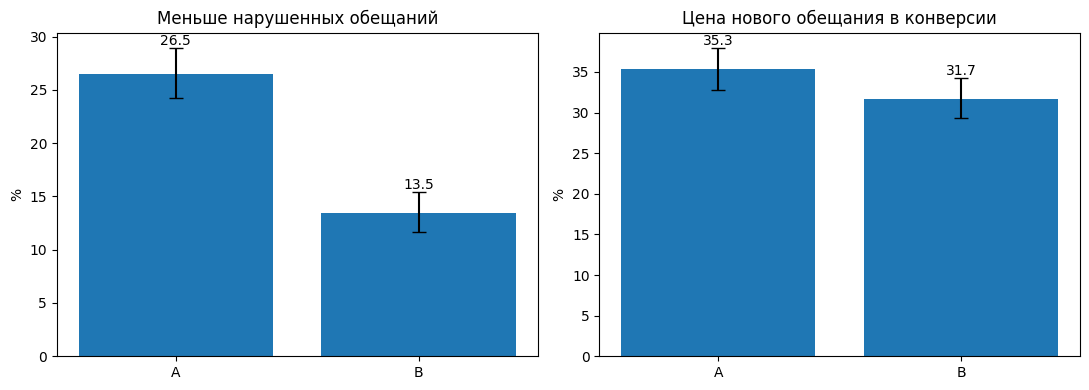

In [7]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
ab=pd.read_csv("ab_promise.csv",parse_dates=["ts"])
orders=ab[ab.ordered.eq(1)]
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,df,metric,title in [(axes[0],orders,"late","Меньше нарушенных обещаний"),(axes[1],ab[ab.distance_km<2],"ordered","Цена нового обещания в конверсии")]:
    g=df.groupby("group")[metric].agg(["sum","size","mean"])
    lo,hi=proportion_confint(g["sum"],g["size"],method="wilson")
    bars=ax.bar(g.index,g["mean"]*100,yerr=[(g["mean"]-lo)*100,(hi-g["mean"])*100],capsize=5)
    ax.bar_label(bars,labels=[f"{v*100:.1f}" for v in g["mean"]])
    ax.set_title(title)
    ax.set_ylabel("%")
fig.tight_layout()
fig.savefig("promise-chart.png",dpi=160,bbox_inches="tight")
plt.show()

## 8. Решение по правилу и ограничения
Функция также применима к отдельному городу; сравнение с −10 выполняется на полной точности.

In [8]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
ab=pd.read_csv("ab_promise.csv",parse_dates=["ts"])
orders=ab[ab.ordered.eq(1)]
def share_result(df,metric):
    a=df.loc[df.group.eq("A"),metric]
    b=df.loc[df.group.eq("B"),metric]
    d=b.mean()-a.mean()
    se=np.sqrt(a.mean()*(1-a.mean())/len(a)+b.mean()*(1-b.mean())/len(b))
    p=proportions_ztest([b.sum(),a.sum()],[len(b),len(a)])[1]
    return a.mean(),b.mean(),d,d-1.96*se,d+1.96*se,p
def promise_report(ab):
    sizes=ab.group.value_counts().sort_index()
    srm_ok=bool(stats.chisquare(sizes).pvalue>=.01)
    o=ab[ab.ordered.eq(1)]
    _,_,ld,_,_,lp=share_result(o,"late")
    _,_,cd,_,_,cp=share_result(ab[ab.distance_km<2],"ordered")
    a=ab.loc[ab.group.eq("A"),"amount"]
    b=ab.loc[ab.group.eq("B"),"amount"]
    rd=b.mean()-a.mean()
    se=np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))
    lo,hi=rd-1.96*se,rd+1.96*se
    rp=stats.ttest_ind(b,a,equal_var=False).pvalue
    if not srm_ok or not(ld<0 and lp<.05) or hi < -10:
        decision="не внедрять"
    elif lo > -10:
        decision="внедрять"
    else:
        decision="неопределённо"
    return {"srm_ok":srm_ok,"late_diff_pp":round(ld*100,1),"late_p":lp,"conv_short_diff_pp":round(cd*100,2),"conv_short_p":cp,"rev_diff":round(rd,1),"rev_p":rp,"rev_lo":round(lo,1),"rev_hi":round(hi,1),"decision":decision}
report=promise_report(ab)
display(pd.Series(report).rename("итог").to_frame())
display(pd.DataFrame({city:promise_report(x) for city,x in ab.groupby("city")}).T)
display(Markdown(f"**Три предложения руководителю.** Решение по заранее записанному правилу — **{report["decision"]}**: до исключения недопустимой потери новый формат массово не запускаем. Доля опозданий среди заказов изменилась на {report["late_diff_pp"]:.1f} п.п. (95% ДИ {ci[0]:.1f}…{ci[1]:.1f}), а выручка на сессию — на {rev_diff_full:.1f} ₽ (95% ДИ {rev_lo_full:.1f}…{rev_hi_full:.1f} ₽), поэтому сравниваем именно этот интервал с −10 ₽. Постоянного ID гостя нет: нельзя проверить повторные назначения и зависимость его сессий, удержание или долгосрочный эффект; новый этап требует заранее заданных объёма и даты анализа."))

,итог
srm_ok,True
late_diff_pp,-13.1
late_p,0.0
conv_short_diff_pp,-3.62
conv_short_p,0.046487
rev_diff,-13.0
rev_p,0.099281
rev_lo,-28.4
rev_hi,2.5
decision,неопределённо


,srm_ok,late_diff_pp,late_p,conv_short_diff_pp,conv_short_p,rev_diff,rev_p,rev_lo,rev_hi,decision
Казань,True,-11.3,0.000024,-0.92,0.762226,-1.3,0.92145,-26.2,23.7,неопределённо
Пермь,True,-10.4,0.000068,-3.87,0.203288,-9.0,0.513749,-36.0,18.0,неопределённо
Тюмень,True,-19.2,0.000001,-6.96,0.154227,-45.3,0.027264,-85.5,-5.1,неопределённо
Уфа,True,-17.2,0.000015,-6.2,0.191276,-17.2,0.399954,-57.1,22.8,неопределённо


**Три предложения руководителю.** Решение по заранее записанному правилу — **неопределённо**: до исключения недопустимой потери новый формат массово не запускаем. Доля опозданий среди заказов изменилась на -13.1 п.п. (95% ДИ -16.1…-10.1), а выручка на сессию — на -13.0 ₽ (95% ДИ -28.4…2.5 ₽), поэтому сравниваем именно этот интервал с −10 ₽. Постоянного ID гостя нет: нельзя проверить повторные назначения и зависимость его сессий, удержание или долгосрочный эффект; новый этап требует заранее заданных объёма и даты анализа.

## Повтор: полная точность и показанные границы

План уже зафиксировал δ=10 ₽. В X и Y исправный SRM (p=0.42), снижение опозданий −8.1 п.п. при p=0.003. До вычисления ожидаю X «внедрять», Y «неопределённо»: −9.96 > −10, а −10.04 < −10 при верхней границе выше порога. Округлённая подпись нижней границы в обоих случаях −10.0 ₽ и не подходит для сравнения.

In [9]:
def decide_from_full_bounds(srm_p, late_diff_pp, late_p, rev_lo, rev_hi, delta=10):
    if srm_p < .01 or not (late_diff_pp < 0 and late_p < .05) or rev_hi < -delta:
        return "не внедрять"
    if rev_lo > -delta:
        return "внедрять"
    return "неопределённо"

boundary_rows = []
for name, lo_full, hi_full in [("X", -9.96, 7.84), ("Y", -10.04, 7.76)]:
    boundary_rows.append({
        "пример": name, "delta": 10, "srm_p": .42,
        "late_diff_pp": -8.1, "late_p": .003,
        "rev_lo_full": lo_full, "rev_hi_full": hi_full,
        "решение": decide_from_full_bounds(.42, -8.1, .003, lo_full, hi_full),
        "нижняя_для_отчёта": f"{lo_full:.1f}",
        "верхняя_для_отчёта": f"{hi_full:.1f}"
    })
boundary_decisions = pd.DataFrame(boundary_rows).set_index("пример")
display(boundary_decisions)
assert boundary_decisions.loc["X", "решение"] == "внедрять"
assert boundary_decisions.loc["Y", "решение"] == "неопределённо"
boundary_decisions.to_json("boundary-decisions.json", orient="index", force_ascii=False, indent=2)


,delta,srm_p,late_diff_pp,late_p,rev_lo_full,rev_hi_full,решение,нижняя_для_отчёта,верхняя_для_отчёта
пример,,,,,,,,,
X,10,0.42,-8.1,0.003,-9.96,7.84,внедрять,-10.0,7.8
Y,10,0.42,-8.1,0.003,-10.04,7.76,неопределённо,-10.0,7.8


### Проверка сохранённых границ по городам

Вызов функции отчёта по срезу допустим после проверки наличия A/B среди всех сессий, заказов и ближней зоны. Полные границы ниже сохраняются рядом с решением и отдельно от округлённого итогового словаря.

In [10]:
full_report_rows = []
for name, x in [("вся выгрузка", ab), *list(ab.groupby("city"))]:
    assert set(x.group) == {"A", "B"}
    assert set(x.loc[x.ordered.eq(1), "group"]) == {"A", "B"}
    assert set(x.loc[x.distance_km < 2, "group"]) == {"A", "B"}
    a_full = x.loc[x.group.eq("A"), "amount"]
    b_full = x.loc[x.group.eq("B"), "amount"]
    difference_full = b_full.mean() - a_full.mean()
    error_full = np.sqrt(a_full.var(ddof=1)/len(a_full) + b_full.var(ddof=1)/len(b_full))
    lower_full, upper_full = difference_full - 1.96*error_full, difference_full + 1.96*error_full
    r = promise_report(x)
    full_report_rows.append({"срез": name, "rev_diff_full": difference_full,
                             "rev_lo_full": lower_full, "rev_hi_full": upper_full,
                             "decision": r["decision"], "shown_lo": f"{lower_full:.1f}",
                             "shown_hi": f"{upper_full:.1f}"})
full_decisions = pd.DataFrame(full_report_rows).set_index("срез")
display(full_decisions)
full_decisions.to_json("promise-full-decisions.json", orient="index", force_ascii=False, indent=2)


,rev_diff_full,rev_lo_full,rev_hi_full,decision,shown_lo,shown_hi
срез,,,,,,
вся выгрузка,-12.979598,-28.411422,2.452226,неопределённо,-28.4,2.5
Казань,-1.253696,-26.170806,23.663413,неопределённо,-26.2,23.7
Пермь,-8.991901,-35.977432,17.993629,неопределённо,-36.0,18.0
Тюмень,-45.340545,-85.544253,-5.136837,неопределённо,-85.5,-5.1
Уфа,-17.162338,-57.112215,22.787539,неопределённо,-57.1,22.8


### Перенос на образовательную платформу
Если программу назначают целым классам, независимой единицей назначения является класс. Ученики одного класса разделяют преподавателя, программу и среду, поэтому считать их независимыми строками в обычном тесте нельзя: это занизит SE. Для первого анализа сравню средний результат по классам; при цели «средний эффект на ученика» заранее уточню веса и применю метод, учитывающий кластеризацию по классу. Размер эксперимента определяется прежде всего числом классов, не только числом учеников.

### Уточнения после повторного чтения

Симуляция подтверждает согласованность вычислений в принятой модели, но не независимость реальных доставок. Доверительный интервал относится к параметру и процедуре; не присваиваю фиксированному среднему вероятность 95%. Для пуша интервал прироста 0.52…3.56 п.п. выше нуля, однако не подтверждает достижение полезного порога 2 п.п.; без данных об отписках полного основания для массового запуска нет. MDE характеризует обнаружение эффекта с заданной мощностью, а бизнес-порог — его полезность.

Выручка на покупателя — условная описательная метрика: состав покупателей мог измениться при назначении варианта. Нельзя по незначимому p объявить её неизменной и доказать, что весь причинный эффект ARPU вызван одной конверсией. В проекте доля опозданий также относится к заказам после назначения; изменение отбора заказов и отсутствие постоянного ID ограничивают перенос результата на тех же людей и долгосрочное удержание.
